# 07. Results Summary: the whole project on one page

**Project:** Buffer Delay Allocation Engine (Analytics Capstone Project, Team T19)
**Team:** Vaibhav Maheshwari (BA05057), Prashansa Naomi Konduru (BA05042), Anil Kumar (BA05008)
**Faculty:** Mr. Nikhil D Jonathan
**Data:** `aa_clean_v1.0.parquet` (tag `data-v1.0`): 1,641,071 American Airlines mainline flights, 1 Jan 2025 to 31 Aug 2026

**What this notebook does.** It does not train anything. It reads the result files saved by notebooks 04, 05 and 06, puts the key numbers in one place, shows the main charts, and states the answer to the project's business question:
*with a fixed daily budget of extra planned ground time, which turnarounds should get it so that the fewest delay minutes are passed on to later flights?*

## How to run this notebook

Run notebooks **04, 05 and 06 first** (each one saves its results in a folder called `modelling_outputs`, or `docs/modelling` inside the project repository). Then open this notebook and choose *Restart and Run All*. It takes a few seconds, needs only pandas and matplotlib, and does **not** need the data file.

| Where you run it | What to do |
|---|---|
| **Your laptop** | Run it from the same folder as notebooks 04 to 06, so it finds `modelling_outputs` next to it. |
| **Google Colab** | If you ran 04, 05 and 06 in the same Colab session, nothing more is needed. Otherwise upload the three files `results_04_passthrough.json`, `results_05_model.json` and `results_06_simulator.json` (and, if you want the charts, the `figures` folder) to the Colab file panel on the left, then run the first code cell. |

## 1. Load the saved results

In [1]:
import json, sys
from pathlib import Path
for module in ["pandas", "matplotlib"]:
    try:
        __import__(module)
    except ImportError:
        raise ImportError(f"Please install {module} (pip install pandas matplotlib), then run this cell again.")
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from IPython.display import display, Markdown
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 40)
say = lambda t: display(Markdown(t))

NEEDED = ["results_04_passthrough.json", "results_05_model.json", "results_06_simulator.json"]
def find_folder():
    here = Path.cwd().resolve()
    cands = []
    for f in [here, *here.parents]:
        cands += [f / "modelling_outputs", f / "docs" / "modelling", f]
    cands += [Path("/content/modelling_outputs"), Path("/content")]
    for c in cands:
        if all((c / n).exists() for n in NEEDED):
            return c
    return None
OUT = find_folder()
if OUT is None:
    raise FileNotFoundError("Could not find the result files from notebooks 04, 05 and 06 (" + ", ".join(NEEDED) + "). "
                            "Run those notebooks first, or upload the three files next to this notebook, then run this cell again.")
R4, R5, R6 = [json.loads((OUT / n).read_text()) for n in NEEDED]
FIG = OUT / "figures"
print("Result files found in:", OUT.name)

Result files found in: modelling_outputs


## 2. How the project fits together

| Step | Notebook | Question it answers | Main product |
|---|---|---|---|
| Data | D2 | Is the data clean and trustworthy? | `aa_clean_v1.0.parquet` |
| Explore | D3 | What patterns exist, and what do we expect? | 8 hypotheses tested, 5 insights |
| Learn the absorption | **04** | How much of an inbound delay does extra ground time absorb? | Pass-through curve |
| Predict the risk | **05** | Which turnarounds will have a delay to absorb, known from the timetable alone? | Two prediction models |
| Decide and test | **06** | Where should a fixed budget of buffer go, and how much better is that than the alternatives? | Allocation engine and simulator |

## 3. The key numbers

**Step 1. The pass-through curve (notebook 04).**

In [2]:
curve = pd.DataFrame(R4["curve"])
cmp_ = pd.DataFrame(R4["curve_vs_line"]); cmp_t = cmp_[cmp_.period == "test"].set_index("predictor")
say(f"""* Delay is passed on almost one-for-one (pass-through about **{curve.smooth.iloc[1]:.2f}**) up to about **{R4['flat_until']:.0f} minutes** of planned ground time. Beyond that it falls steadily, to **{curve.smooth.iloc[-1]:.2f}** over four hours.
* On the unseen test period the curve predicts the outbound delay with an average error of **{cmp_t.loc['3 Curve','MAE']:.1f} min** (one straight line: {cmp_t.loc['2 One straight line','MAE']:.1f} min; R² {cmp_t.loc['3 Curve','R2']:.2f} against {cmp_t.loc['2 One straight line','R2']:.2f}).
* Extra minutes pay off most when a turnaround already has about **{R4['best_start']:.0f} minutes**; on turnarounds shorter than about an hour, ten extra minutes absorb almost nothing.""")

* Delay is passed on almost one-for-one (pass-through about **0.99**) up to about **63 minutes** of planned ground time. Beyond that it falls steadily, to **0.07** over four hours.
* On the unseen test period the curve predicts the outbound delay with an average error of **19.2 min** (one straight line: 27.4 min; R² 0.53 against 0.31).
* Extra minutes pay off most when a turnaround already has about **120 minutes**; on turnarounds shorter than about an hour, ten extra minutes absorb almost nothing.

**Step 2. The risk models (notebook 05), on the test period (Jan to Aug 2026).**

In [3]:
cl = pd.DataFrame(R5["model_A_classification"]); cl_t = cl[cl.period == "test"].set_index("predictor")
rg = pd.DataFrame(R5["model_A_regression"]); rg_t = rg[rg.period == "test"].set_index("predictor")
L = R5["lift"]; MB = pd.DataFrame(R5["model_B"]).set_index("period")
say(f"""* **"Will the next flight be 15+ min late?"** AUC **{L['auc']:.3f}** (coin toss 0.5; airport-and-hour average {L['auc_baseline']:.3f}). The riskiest tenth of turnarounds is late **{100*L['top_decile']:.0f}%** of the time, the safest tenth **{100*L['bottom_decile']:.0f}%**.
* **Outbound delay in minutes:** average error {rg_t.loc['4 LightGBM model','MAE']:.1f} min against {rg_t.loc['1 Training average','MAE']:.1f} for the average, R² {rg_t.loc['4 LightGBM model','R2']:.2f}. This is modest, as expected when only the timetable is known.
* **Inbound risk (what needs absorbing):** rank correlation {MB.loc['test','rank_correlation']:.2f}; the riskiest tenth has **{R5['inbound_ratio_top_bottom']:.0f} times** the inbound delay of the safest tenth.""")

* **"Will the next flight be 15+ min late?"** AUC **0.703** (coin toss 0.5; airport-and-hour average 0.619). The riskiest tenth of turnarounds is late **64%** of the time, the safest tenth **11%**.
* **Outbound delay in minutes:** average error 25.0 min against 26.8 for the average, R² 0.07. This is modest, as expected when only the timetable is known.
* **Inbound risk (what needs absorbing):** rank correlation 0.31; the riskiest tenth has **15 times** the inbound delay of the safest tenth.

**Step 3. The allocation engine (notebook 06), budget of 5 extra minutes per turnaround on average.**

In [4]:
ta = pd.DataFrame(R6["table_all"]).set_index("strategy"); tn = pd.DataFrame(R6["table_normal"]).set_index("strategy"); ts = pd.DataFrame(R6["table_storm"]).set_index("strategy")
cit = pd.DataFrame(R6["engine_ratio_ci"])
summary = pd.DataFrame({
    "absorbed, all days (min)": ta.absorbed_min, "% of passed-on delay removed": ta.pct_removed,
    "absorbed per 100 buffer min (normal days)": tn.absorbed_per_100_added, "absorbed per 100 buffer min (disruption days)": ts.absorbed_per_100_added,
    "late departures avoided per 1,000": ta.late_avoided_per_1000}).round(1)
display(summary)
u5 = cit[(cit.compared_with == "Spread evenly") & (cit.budget_min_per_turnaround == 5)].iloc[0]
r5 = cit[(cit.compared_with == "Riskiest first") & (cit.budget_min_per_turnaround == 5)].iloc[0]
E = "Engine (our method)"
say(f"""* For the same budget, the engine absorbs **{u5.engine_vs_it:.1f} times** the delay of spreading buffer evenly (95% range {u5.low_95:.1f}x to {u5.high_95:.1f}x) and **{r5.engine_vs_it:.2f} times** that of "riskiest first".
* It removes **{ta.loc[E,'pct_removed']:.1f}%** of the delay that is passed on at this budget, and reaches **{100*ta.loc[E,'absorbed_min']/ta.loc['Hindsight (not possible)','absorbed_min']:.0f}%** of the best possible result with perfect foresight.
* It works on disruption days too ({ts.loc[E,'absorbed_per_100_added']:.0f} against {ts.loc[('Spread evenly'),'absorbed_per_100_added']:.0f} minutes absorbed per 100 buffer minutes for even spreading).""")

,"absorbed, all days (min)",% of passed-on delay removed,absorbed per 100 buffer min (normal days),absorbed per 100 buffer min (disruption days),"late departures avoided per 1,000"
strategy,,,,,
No buffer,0.0,0.0,0.0,0.0,0.0
Spread evenly,67189.7,1.3,3.1,5.6,2.8
Shortest first,41928.9,0.8,1.9,3.5,0.9
Riskiest first,223325.6,4.4,10.3,15.7,4.1
Engine (our method),271116.5,5.3,12.4,20.5,5.5
Hindsight (not possible),536229.4,10.6,24.7,38.9,9.1


* For the same budget, the engine absorbs **4.0 times** the delay of spreading buffer evenly (95% range 4.0x to 4.1x) and **1.21 times** that of "riskiest first".
* It removes **5.3%** of the delay that is passed on at this budget, and reaches **51%** of the best possible result with perfect foresight.
* It works on disruption days too (21 against 6 minutes absorbed per 100 buffer minutes for even spreading).

## 4. The main charts

Saved by the earlier notebooks. If a chart is missing, run the notebook that makes it.

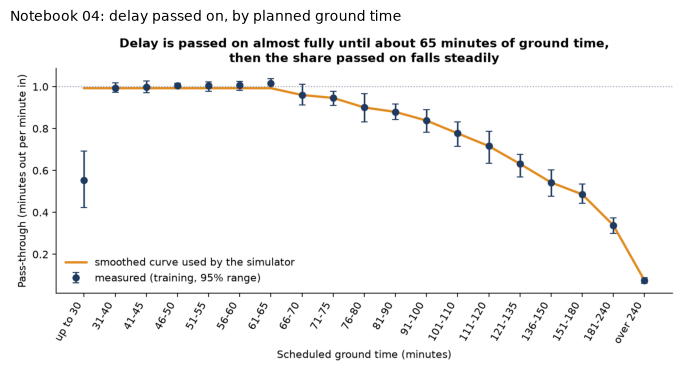

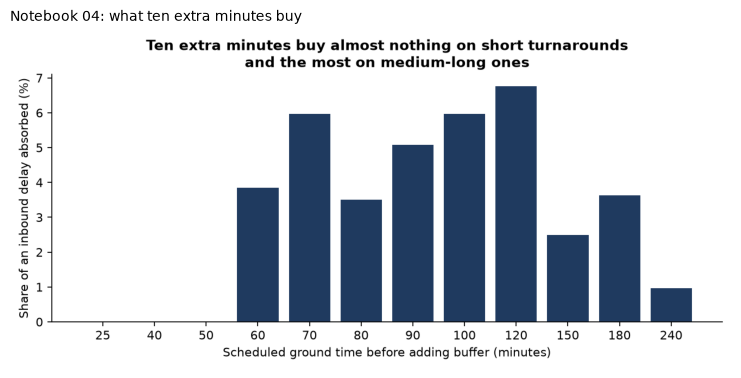

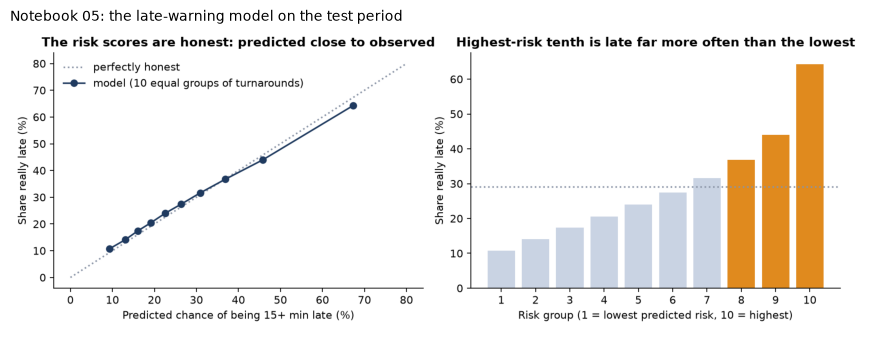

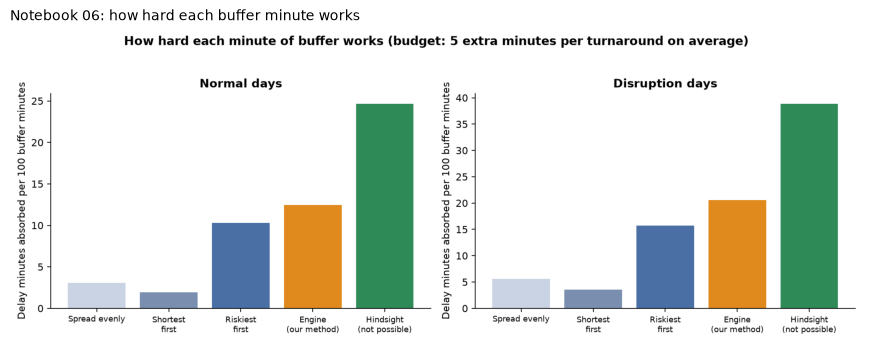

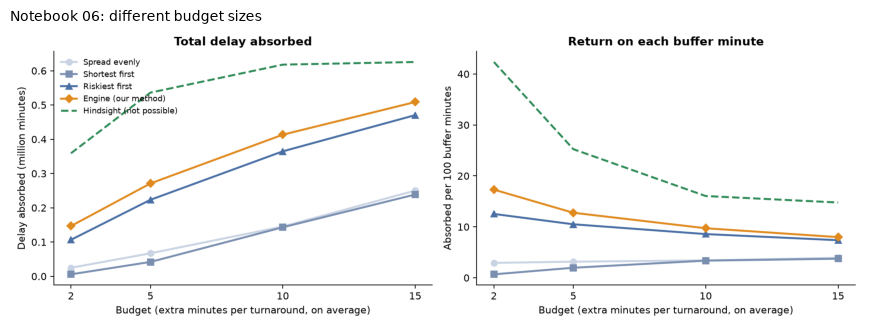

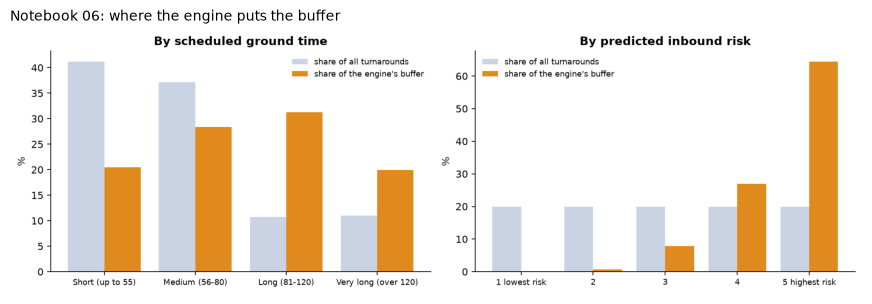

In [5]:
SHOW = [("fig04_passthrough_curve", "Notebook 04: delay passed on, by planned ground time"),
        ("fig05_gain_of_ten_minutes", "Notebook 04: what ten extra minutes buy"),
        ("fig07_late_warning_test", "Notebook 05: the late-warning model on the test period"),
        ("fig12_efficiency_by_strategy", "Notebook 06: how hard each buffer minute works"),
        ("fig13_budget_sweep", "Notebook 06: different budget sizes"),
        ("fig14_where_buffer_goes", "Notebook 06: where the engine puts the buffer")]
for name, title in SHOW:
    f = FIG / f"{name}.png"
    if f.exists():
        fig, ax = plt.subplots(figsize=(11, 4.4)); ax.imshow(mpimg.imread(f)); ax.axis("off"); ax.set_title(title, fontsize=10, loc="left"); plt.show()
    else:
        print("(chart not found:", name, ")")

## 5. The answer, and what we recommend

**Answer to the business question.** Where the buffer goes matters more than how much of it there is. A budget spread evenly over all turnarounds is used poorly,
because (1) most turnarounds are short, and minutes added to a turnaround of under about an hour absorb almost no delay, and (2) most turnarounds are not late to begin with.
Putting the same budget on turnarounds that are **long enough to absorb** and **likely to receive a late aircraft** absorbs several times more delay.

**Recommended rule of thumb for the airline's schedulers**, which the engine formalises:
1. Do not add small amounts of buffer to turnarounds that are already short. Either add enough to move them into the range where absorption starts, or leave them.
2. Rank turnarounds by timetable risk (airport, hour, aircraft's position in its day, route) and give the largest blocks to the top-risk fifth.
3. Check the plan with and without disruption days. The engine's advantage holds in both, but the gain per buffer minute is larger on disruption days.

In [6]:
w = R6["where"]; sweep = pd.DataFrame(R6["sweep"])
b_ = sweep[(sweep.strategy == E)].set_index("budget")
say(f"""**What the engine actually does (budget of 5 minutes per turnaround):** it gives {100*(w['by_risk']['engine']['5 highest risk']/100):.0f}% of the buffer to the highest-risk fifth of turnarounds and almost none to the safest two fifths;
it gives {100*sum(v for k, v in w['by_band']['engine'].items() if k.startswith(('Long', 'Very'))) / 100:.0f}% of the buffer to turnarounds that already have more than 80 minutes, because that is where extra minutes absorb the most.

**Bigger budgets help, with diminishing returns.** Delay absorbed per 100 buffer minutes by the engine: {', '.join(f'{b_.loc[k,"absorbed_per_100_added"]:.0f} at {k} min' for k in b_.index)} per turnaround.
The first minutes are the most valuable; each further minute is worth less.""")

**What the engine actually does (budget of 5 minutes per turnaround):** it gives 64% of the buffer to the highest-risk fifth of turnarounds and almost none to the safest two fifths;
it gives 51% of the buffer to turnarounds that already have more than 80 minutes, because that is where extra minutes absorb the most.

**Bigger budgets help, with diminishing returns.** Delay absorbed per 100 buffer minutes by the engine: 17 at 2 min, 13 at 5 min, 10 at 10 min, 8 at 15 min per turnaround.
The first minutes are the most valuable; each further minute is worth less.

## 6. Limits, stated plainly

* **Association, not cause.** The pass-through curve is measured from how delay behaved in the past, not from an experiment where buffer was added. A late inbound flight and a late outbound flight can share a cause (weather, congestion). The absorbed-minute totals are therefore **upper bounds**, and the *ranking* of strategies is more reliable than the absolute numbers. In notebook 06 the ranking survived two harsher versions of the curve.
* **Buffer has a price.** Extra ground time uses aircraft time and can shift later flights. We compare strategies at the same total budget, but we do not put a price on the minutes.
* **A timetable-only model is modest.** It ranks turnarounds well, but it cannot predict the exact delay of a single flight, because weather, faults and crew are not in the timetable.
* **Scope.** One airline (American Airlines mainline), domestic flights, Jan 2025 to Aug 2026, and only turnarounds where both flights operated. Each calendar month appears once or twice.
* **Replay, not rollout.** The simulator replays the past under different rules. It cannot show how the airline would adapt its schedules or aircraft assignments.

## 7. Reproducibility checklist

| Item | Where |
|---|---|
| Data file and its checksum | `aa_clean_v1.0.parquet`, tag `data-v1.0`, SHA-256 checked inside notebooks 04, 05 and 06 |
| Train / validation / test | Jan to Sep 2025 / Oct to Dec 2025 / Jan to Aug 2026; the test period is used only for final numbers |
| Random seed | 42 in every notebook |
| Banned inputs for prediction | Actual delays, times, cancellations and disruption days are never used as inputs (checked by code in notebook 05) |
| Results saved | `results_04_passthrough.json`, `results_05_model.json`, `results_06_simulator.json`, `passthrough_curve.csv` and the `figures` folder |